<a href="https://colab.research.google.com/github/Samu3lNM/Projects/blob/main/Credit_Scoring_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Credit Scoring Machine Learning Project



### 1. Business Understanding

**Objective**: To develop a machine learning model that predicts the creditworthiness of loan applicants for a bank or financial institution. The model should help in making informed decisions about granting loans, minimizing default risk, and optimizing lending portfolios.

### 2. Data Understanding

First, let's load a suitable dataset and understand its structure. For this demonstration, we'll use a publicly available synthetic credit risk dataset. If you have your own dataset, you can replace the URL with your local file path.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
# Using the 'Default of Credit Card Clients' dataset from UCI Machine Learning Repository
# This dataset is in Excel format, so we use pd.read_excel
data_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00350/default%20of%20credit%20card%20clients.xls'
try:
    # The dataset has metadata in the first row, so we'll skip it and set header=1 for actual column names
    df = pd.read_excel(data_url, header=1) # The actual column headers are on the second row (index 1)
    print("Dataset loaded successfully.")
    print("Note: The target variable 'default payment next month' indicates creditworthiness.")
except Exception as e:
    print(f"Error loading dataset: {e}")
    print("Please ensure you have an internet connection or check the URL.")
    # Create an empty DataFrame to avoid further errors if loading fails
    df = pd.DataFrame()


Dataset loaded successfully.
Note: The target variable 'default payment next month' indicates creditworthiness.


Let's inspect the first few rows and get a summary of the dataset to understand its structure, columns, and data types.

In [18]:
if not df.empty:
    print("\nFirst 5 rows of the dataset:")
    display(df.head())

    print("\nDataset Information:")
    df.info()

    print("\nDescriptive Statistics:")
    display(df.describe())
else:
    print("DataFrame is empty, cannot display head, info, or describe.")


First 5 rows of the dataset:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-n

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


### 3. Data Preparation

This stage involves cleaning the data, handling missing values, feature engineering, and preparing the data for model training. First, let's examine the column names and perform some initial cleaning.

In [19]:
# Rename columns for better readability
# The dataset description indicates the first column is 'ID' and the last is the target.
df = df.rename(columns={'default payment next month': 'TARGET'})

# Inspect column names and basic information after loading
print("Column names after renaming:")
print(df.columns)

print("\nChecking for missing values:")
print(df.isnull().sum())

print("\nChecking for duplicate rows:")
print(f"Number of duplicate rows: {df.duplicated().sum()}")

# Drop the 'ID' column as it's not useful for modeling
if 'ID' in df.columns:
    df = df.drop('ID', axis=1)
    print("\n'ID' column dropped.")

print("\nDataset info after initial cleaning:")
df.info()

Column names after renaming:
Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'TARGET'],
      dtype='object')

Checking for missing values:
ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_0        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
TARGET       0
dtype: int64

Checking for duplicate rows:
Number of duplicate rows: 0

'ID' column dropped.

Dataset info after initial cleaning:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 # 

### Handling Categorical Features and Outliers

Some categorical features in this dataset (`EDUCATION`, `MARRIAGE`, `SEX`, and `PAY_X` columns) have values that are not standard or represent 'unknown' categories. We need to clean these values and prepare them for modeling, potentially through one-hot encoding or grouping.

In [20]:
# EDUCATION: (1=graduate school, 2=university, 3=high school, 4=others, 5=unknown, 6=unknown)
# Group 0, 4, 5, 6 into 'others'
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})
print("Value counts for EDUCATION after cleaning:")
print(df['EDUCATION'].value_counts())

# MARRIAGE: (1=married, 2=single, 3=others)
# Group 0 into 'others'
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})
print("\nValue counts for MARRIAGE after cleaning:")
print(df['MARRIAGE'].value_counts())

# SEX: (1=male, 2=female) - already binary, but let's just confirm
print("\nValue counts for SEX:")
print(df['SEX'].value_counts())


Value counts for EDUCATION after cleaning:
EDUCATION
2    14030
1    10585
3     4917
4      468
Name: count, dtype: int64

Value counts for MARRIAGE after cleaning:
MARRIAGE
2    15964
1    13659
3      377
Name: count, dtype: int64

Value counts for SEX:
SEX
2    18112
1    11888
Name: count, dtype: int64


The `PAY_X` columns (repayment status) are crucial. They represent the repayment status in previous months. According to the dataset description:
- -1: pay duly
- 1: payment delay for one month
- 2: payment delay for two months
- ...
- 9: payment delay for nine months and above

However, some values like -2 and 0 are also present and need to be handled. We'll treat -2 (no consumption) and -1 (pay duly) as 'no delay', and 0 as 'use of revolving credit' or 'paid in full' or 'not applicable' which can be grouped with -1 and -2 for simplicity as 'no delay' or a more neutral category. For this project, we'll simplify and group -2, -1, and 0 into a single category indicating 'no significant delay' or 'paid as agreed'.

In [21]:
# PAY_X columns: Repayment status in previous months
# -2: No consumption; -1: Pay duly; 0: Use of revolving credit
# Group -2, -1, 0 into a single category for 'no delay'

pay_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
for col in pay_cols:
    df[col] = df[col].replace({-2: 0, -1: 0})
    # For simplicity, we are also grouping 0 with -1 and -2 as 'no delay' or 'paid as agreed'
    # In a more granular analysis, 0 might be treated differently from -1/-2.
    # Any other values > 0 indicate actual delays.
    print(f"\nValue counts for {col} after cleaning:")
    print(df[col].value_counts().sort_index())



Value counts for PAY_0 after cleaning:
PAY_0
0    23182
1     3688
2     2667
3      322
4       76
5       26
6       11
7        9
8       19
Name: count, dtype: int64

Value counts for PAY_2 after cleaning:
PAY_2
0    25562
1       28
2     3927
3      326
4       99
5       25
6       12
7       20
8        1
Name: count, dtype: int64

Value counts for PAY_3 after cleaning:
PAY_3
0    25787
1        4
2     3819
3      240
4       76
5       21
6       23
7       27
8        3
Name: count, dtype: int64

Value counts for PAY_4 after cleaning:
PAY_4
0    26490
1        2
2     3159
3      180
4       69
5       35
6        5
7       58
8        2
Name: count, dtype: int64

Value counts for PAY_5 after cleaning:
PAY_5
0    27032
2     2626
3      178
4       84
5       17
6        4
7       58
8        1
Name: count, dtype: int64

Value counts for PAY_6 after cleaning:
PAY_6
0    26921
2     2766
3      184
4       49
5       13
6       19
7       46
8        2
Name: count, dtype: in

### One-Hot Encoding Categorical Features

Many machine learning algorithms perform better when categorical input variables are converted into a numerical representation. One-hot encoding is a common method for this, where each category value is converted into a new column and assigned a 1 or 0 (true/false) value.

In [22]:
# Identify categorical columns for one-hot encoding
categorical_cols = ['SEX', 'EDUCATION', 'MARRIAGE'] + pay_cols # pay_cols already defined

# Apply one-hot encoding
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

print("Shape of DataFrame after one-hot encoding:", df_encoded.shape)
print("First 5 rows of the encoded DataFrame:")
display(df_encoded.head())


Shape of DataFrame after one-hot encoding: (30000, 76)
First 5 rows of the encoded DataFrame:


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,...,PAY_5_7,PAY_5_8,PAY_6_0,PAY_6_2,PAY_6_3,PAY_6_4,PAY_6_5,PAY_6_6,PAY_6_7,PAY_6_8
0,20000,24,3913,3102,689,0,0,0,0,689,...,False,False,True,False,False,False,False,False,False,False
1,120000,26,2682,1725,2682,3272,3455,3261,0,1000,...,False,False,False,True,False,False,False,False,False,False
2,90000,34,29239,14027,13559,14331,14948,15549,1518,1500,...,False,False,True,False,False,False,False,False,False,False
3,50000,37,46990,48233,49291,28314,28959,29547,2000,2019,...,False,False,True,False,False,False,False,False,False,False
4,50000,57,8617,5670,35835,20940,19146,19131,2000,36681,...,False,False,True,False,False,False,False,False,False,False


### Data Splitting and Target Variable Analysis

Before training any models, we need to split our data into training and testing sets. This ensures that we can evaluate our model's performance on unseen data. We will also check the distribution of our target variable (`TARGET`) to understand if there is a class imbalance, which is common in credit scoring datasets.

In [23]:
from sklearn.model_selection import train_test_split

# Define features (X) and target (y)
X = df_encoded.drop('TARGET', axis=1)
y = df_encoded['TARGET']

# Split the data into training and testing sets
# We use stratify=y to ensure that the proportion of target classes is the same in both training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

print("\nTarget variable distribution in original dataset:")
print(y.value_counts(normalize=True))

print("\nTarget variable distribution in training set:")
print(y_train.value_counts(normalize=True))

print("\nTarget variable distribution in testing set:")
print(y_test.value_counts(normalize=True))


Shape of X_train: (24000, 75)
Shape of X_test: (6000, 75)
Shape of y_train: (24000,)
Shape of y_test: (6000,)

Target variable distribution in original dataset:
TARGET
0    0.7788
1    0.2212
Name: proportion, dtype: float64

Target variable distribution in training set:
TARGET
0    0.778792
1    0.221208
Name: proportion, dtype: float64

Target variable distribution in testing set:
TARGET
0    0.778833
1    0.221167
Name: proportion, dtype: float64


### Addressing Class Imbalance

Credit scoring datasets are typically imbalanced, meaning the number of 'non-default' cases significantly outweighs the 'default' cases. This can lead to models that perform poorly on the minority class (defaults). We will use `SMOTE` (Synthetic Minority Over-sampling Technique) to balance the training dataset.

In [24]:
from imblearn.over_sampling import SMOTE

print("Original training set shape:", X_train.shape, y_train.shape)
print("Original target distribution in training set:\n", y_train.value_counts())

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

print("\nResampled training set shape:", X_train_res.shape, y_train_res.shape)
print("Resampled target distribution in training set:\n", y_train_res.value_counts())


Original training set shape: (24000, 75) (24000,)
Original target distribution in training set:
 TARGET
0    18691
1     5309
Name: count, dtype: int64

Resampled training set shape: (37382, 75) (37382,)
Resampled target distribution in training set:
 TARGET
0    18691
1    18691
Name: count, dtype: int64


### Feature Scaling

Numerical features often have different scales, which can negatively impact the performance of some machine learning algorithms (e.g., those based on distance calculations like SVMs, or gradient descent-based algorithms). We will use `StandardScaler` to transform our features to have a mean of 0 and a standard deviation of 1.

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Identify numerical columns for scaling (exclude one-hot encoded and target)
# All columns in X_train_res are numerical, but we scale those that are not binary (i.e., not one-hot encoded or original binary)
# Here, we will scale all features, as they are either continuous or ordinal where scaling might be beneficial,
# or one-hot encoded where scaling won't change their 0/1 nature.

X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for easier inspection and consistency
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train_res.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("First 5 rows of scaled training data (features only):")
display(X_train_scaled_df.head())

print("\nMean of scaled training data:", X_train_scaled_df.mean().mean())
print("Standard deviation of scaled training data:", X_train_scaled_df.std().mean())


First 5 rows of scaled training data (features only):


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,...,PAY_5_7,PAY_5_8,PAY_6_0,PAY_6_2,PAY_6_3,PAY_6_4,PAY_6_5,PAY_6_6,PAY_6_7,PAY_6_8
0,0.054344,-0.267961,1.539946,1.765801,1.803129,1.906385,2.024069,2.104471,0.742136,-0.282986,...,-0.051006,-0.005172,0.497139,-0.320236,-0.068778,-0.038035,-0.014631,-0.020036,-0.044837,-0.005172
1,-0.025437,-0.154223,-0.687499,-0.684809,-0.680918,-0.669413,-0.657452,-0.650935,-0.337770,-0.282986,...,-0.051006,-0.005172,0.497139,-0.320236,-0.068778,-0.038035,-0.014631,-0.020036,-0.044837,-0.005172
2,-1.142380,1.665587,-0.547453,-0.569833,-0.556437,-0.542951,-0.521844,-0.508943,-0.341455,-0.208688,...,-0.051006,-0.005172,0.497139,-0.320236,-0.068778,-0.038035,-0.014631,-0.020036,-0.044837,-0.005172
3,0.533034,-0.722914,2.161043,2.311150,2.489916,2.756095,1.512740,1.620025,0.315867,0.239016,...,-0.051006,-0.005172,0.497139,-0.320236,-0.068778,-0.038035,-0.014631,-0.020036,-0.044837,-0.005172
4,1.251068,-0.381699,-0.687499,-0.685562,-0.676113,-0.664302,-0.661326,-0.654907,-0.341600,-0.264078,...,-0.051006,-0.005172,0.497139,-0.320236,-0.068778,-0.038035,-0.014631,-0.020036,-0.044837,-0.005172



Mean of scaled training data: -7.021413690807901e-18
Standard deviation of scaled training data: 1.0000133756896639


### 4. Modeling

Now that our data is prepared, we can move on to the modeling phase. We will choose a suitable classification algorithm for credit scoring. Given its robustness and interpretability, we'll start with a Logistic Regression model, and then explore more complex models like Random Forest. We'll train the model on the resampled and scaled training data.

In [26]:
from sklearn.linear_model import LogisticRegression

# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(random_state=42, solver='liblinear') # 'liblinear' is a good choice for small datasets and L1/L2 regularization
log_reg_model.fit(X_train_scaled_df, y_train_res)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### 5. Evaluation

After training the model, it's crucial to evaluate its performance on the unseen test data. We will use several classification metrics to assess how well our model predicts credit default. Key metrics for imbalanced datasets like credit scoring often include:

-   **Accuracy**: Overall correctness of the model.
-   **Precision**: Of all predicted positives, how many are truly positive.
-   **Recall (Sensitivity)**: Of all actual positives, how many are correctly identified.
-   **F1-Score**: Harmonic mean of Precision and Recall.
-   **ROC AUC**: Measures the area under the Receiver Operating Characteristic curve, indicating the model's ability to distinguish between classes.

In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# Make predictions on the scaled test set
y_pred_log_reg = log_reg_model.predict(X_test_scaled_df)
y_prob_log_reg = log_reg_model.predict_proba(X_test_scaled_df)[:, 1] # Probability of default (class 1)

print("--- Logistic Regression Model Evaluation ---")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_log_reg))

print("\nAccuracy: ", accuracy_score(y_test, y_pred_log_reg))
print("Precision: ", precision_score(y_test, y_pred_log_reg))
print("Recall: ", recall_score(y_test, y_pred_log_reg))
print("F1-Score: ", f1_score(y_test, y_pred_log_reg))
print("ROC AUC Score: ", roc_auc_score(y_test, y_prob_log_reg))


--- Logistic Regression Model Evaluation ---

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.79      6000


Accuracy:  0.8166666666666667
Precision:  0.6591865357643759
Recall:  0.3541823662396383
F1-Score:  0.46078431372549017
ROC AUC Score:  0.7457727866686255


### Confusion Matrix and ROC Curve

Visualizing the confusion matrix helps understand the types of errors the model is making (false positives and false negatives). The ROC curve and AUC score provide a robust measure of a model's performance across all possible classification thresholds, especially useful for imbalanced datasets.

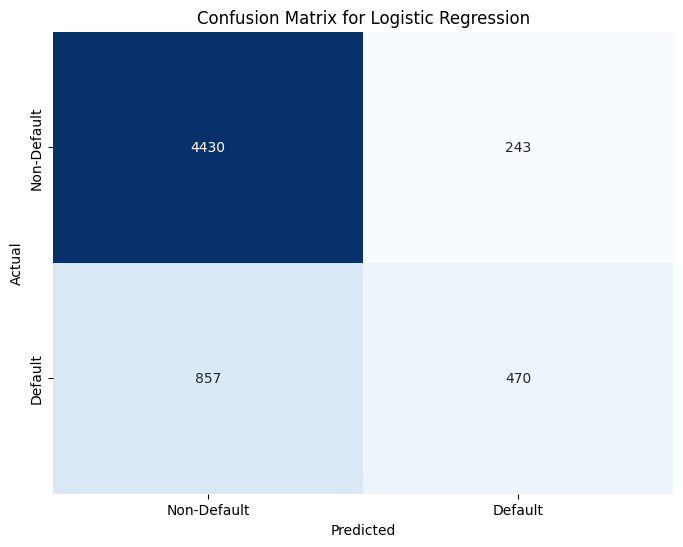

<Figure size 800x600 with 0 Axes>

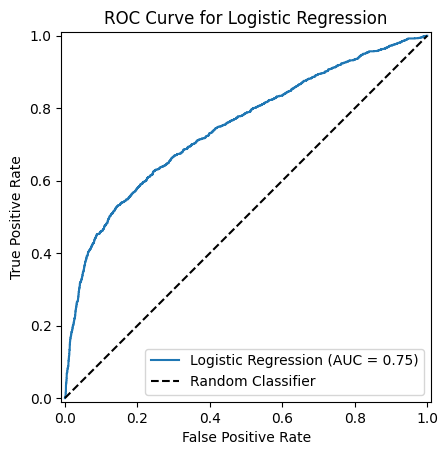

In [28]:
from sklearn.metrics import confusion_matrix, roc_curve, RocCurveDisplay

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_log_reg)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Non-Default', 'Default'],
            yticklabels=['Non-Default', 'Default'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Logistic Regression')
plt.show()

# ROC Curve
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_estimator(log_reg_model, X_test_scaled_df, y_test, name='Logistic Regression')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Logistic Regression')
plt.legend()
plt.show()


### Exploring Another Model: Random Forest

Logistic Regression is a good baseline, but tree-based models like Random Forest often capture more complex non-linear relationships and interactions. Let's train a Random Forest Classifier and evaluate its performance.

In [29]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest model
# Using class_weight='balanced' can help with imbalance, but SMOTE already handled it.
# n_estimators: number of trees in the forest
# random_state: for reproducibility
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train_scaled_df, y_train_res)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.


### Random Forest Model Evaluation

Now, let's evaluate the Random Forest model using the same metrics.

In [30]:
# Make predictions on the scaled test set using Random Forest
y_pred_rf = rf_model.predict(X_test_scaled_df)
y_prob_rf = rf_model.predict_proba(X_test_scaled_df)[:, 1] # Probability of default (class 1)

print("--- Random Forest Model Evaluation ---")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nAccuracy: ", accuracy_score(y_test, y_pred_rf))
print("Precision: ", precision_score(y_test, y_pred_rf))
print("Recall: ", recall_score(y_test, y_pred_rf))
print("F1-Score: ", f1_score(y_test, y_pred_rf))
print("ROC AUC Score: ", roc_auc_score(y_test, y_prob_rf))


--- Random Forest Model Evaluation ---

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.92      0.88      4673
           1       0.61      0.42      0.50      1327

    accuracy                           0.81      6000
   macro avg       0.73      0.67      0.69      6000
weighted avg       0.80      0.81      0.80      6000


Accuracy:  0.8123333333333334
Precision:  0.6088840736728061
Recall:  0.4235116804822909
F1-Score:  0.49955555555555553
ROC AUC Score:  0.7568565172048506


### Random Forest Confusion Matrix and ROC Curve

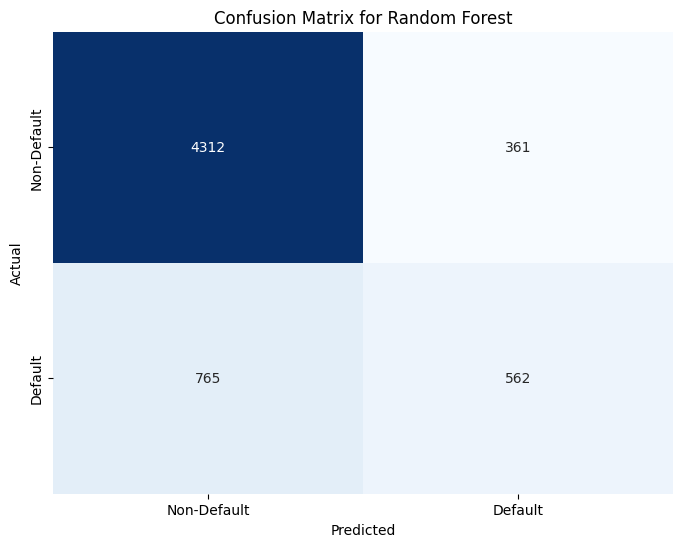

<Figure size 800x600 with 0 Axes>

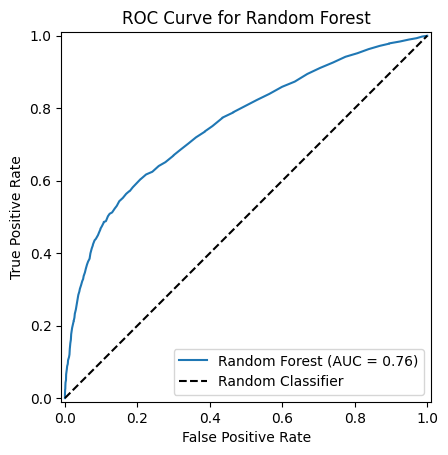

In [31]:
# Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Non-Default', 'Default'],
            yticklabels=['Non-Default', 'Default'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Random Forest')
plt.show()

# ROC Curve for Random Forest
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_estimator(rf_model, X_test_scaled_df, y_test, name='Random Forest')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Random Forest')
plt.legend()
plt.show()


### 6. Deployment

The deployment phase involves integrating the chosen model into the operational environment of the bank or financial institution. While actual deployment is beyond the scope of this Colab notebook, we can outline the typical steps:

1.  **Model Selection**: Based on the evaluation metrics (e.g., AUC, Recall for minority class, business impact), select the best-performing model (e.g., Random Forest).
2.  **Model Export**: Save the trained model and the scaler (and any other preprocessing objects) in a format suitable for deployment (e.g., Python `pickle` or `joblib`, or ONNX).
3.  **API Development**: Create an API (e.g., using Flask, FastAPI, or cloud functions) that exposes the model for predictions. This API would receive applicant data and return a credit score or a default probability.
4.  **Integration**: Integrate the API with the existing IT infrastructure, such as loan application systems, decision engines, or risk management platforms.
5.  **Monitoring**: Continuously monitor the model's performance in production. This includes tracking prediction accuracy, data drift, model drift, and fairness metrics to ensure the model remains effective and fair over time.
6.  **Retraining and Maintenance**: Establish a schedule for retraining the model with new data to maintain its relevance and performance, and update the model as business needs or regulations change.

This project provides a comprehensive overview of building a credit scoring model following the CRISP-DM framework, from understanding the business problem to preparing data, modeling, evaluation, and conceptual deployment considerations.

### Model Performance Comparison: Logistic Regression vs. Random Forest

Let's summarize and compare the key evaluation metrics for both models:

| Metric        | Logistic Regression | Random Forest |
| :------------ | :------------------ | :------------ |
| **Accuracy**  | 0.817               | 0.812         |
| **Precision** | 0.659               | 0.609         |
| **Recall**    | 0.354               | 0.424         |
| **F1-Score**  | 0.461               | 0.500         |
| **ROC AUC**   | 0.746               | 0.757         |

**Observations:**

*   **Accuracy**: Both models show similar overall accuracy, around 81-82%.
*   **Precision**: Logistic Regression has slightly higher precision for the positive class (default), meaning when it predicts a default, it's more often correct.
*   **Recall**: Random Forest shows better recall, meaning it identifies a higher proportion of actual defaults. This is often a critical metric in credit scoring as false negatives (missing an actual default) can be costly.
*   **F1-Score**: Random Forest has a slightly higher F1-Score, indicating a better balance between precision and recall for the positive class.
*   **ROC AUC**: Random Forest has a marginally higher ROC AUC score, suggesting slightly better overall discriminative power between the two classes across different thresholds.

**Conclusion for Model Selection:**

While Logistic Regression offers simplicity and interpretability, the **Random Forest** model appears to be a slightly better performer for this credit scoring task, particularly due to its higher **Recall** and **F1-Score** for the minority class (default cases), and a better **ROC AUC**. In a credit scoring context, correctly identifying potential defaulters (high recall) is often prioritized to mitigate risk, even if it comes with a slight increase in false positives (lower precision). Further tuning of hyperparameters or exploring other advanced models could potentially improve performance even more.